In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [48]:
df = pd.read_csv("VNL2023.csv")

In [49]:
df.isnull().sum()

Player      0
Country     0
Age         0
Attack      0
Block       0
Serve       0
Set         0
Dig         0
Receive     0
Position    0
dtype: int64

In [50]:
df.shape

(131, 10)

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Player    131 non-null    object 
 1   Country   131 non-null    object 
 2   Age       131 non-null    int64  
 3   Attack    131 non-null    float64
 4   Block     131 non-null    float64
 5   Serve     131 non-null    float64
 6   Set       131 non-null    float64
 7   Dig       131 non-null    float64
 8   Receive   131 non-null    float64
 9   Position  131 non-null    object 
dtypes: float64(6), int64(1), object(3)
memory usage: 10.4+ KB


In [52]:
df.describe()

,Age,Attack,Block,Serve,Set,Dig,Receive
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,27.809160,5.642672,0.845573,0.535802,2.192595,3.428397,1.684198
std,4.186268,4.256229,0.700896,0.454346,6.031587,2.077823,1.989939
min,19.000000,0.000000,0.000000,0.000000,0.000000,0.530000,0.000000
25%,25.000000,2.800000,0.370000,0.240000,0.000000,1.920000,0.000000
50%,27.000000,5.170000,0.690000,0.420000,0.000000,3.000000,0.330000
75%,30.000000,8.600000,1.140000,0.760000,0.000000,4.510000,3.385000
max,41.000000,15.800000,4.080000,2.080000,26.890000,11.440000,6.690000


In [53]:
int_col = df.select_dtypes(include=['number'])

In [54]:
corr = int_col.corr()

In [55]:
corr

,Age,Attack,Block,Serve,Set,Dig,Receive
Age,1.000000,-0.177849,-0.101040,-0.108367,0.177757,0.167141,-0.011067
Attack,-0.177849,1.000000,0.338412,0.768859,-0.430805,-0.098999,0.169892
Block,-0.101040,0.338412,1.000000,0.335954,-0.132019,-0.348347,-0.265206
Serve,-0.108367,0.768859,0.335954,1.000000,-0.154815,-0.052501,0.039642
Set,0.177757,-0.430805,-0.132019,-0.154815,1.000000,0.131659,-0.305869
Dig,0.167141,-0.098999,-0.348347,-0.052501,0.131659,1.000000,0.624733
Receive,-0.011067,0.169892,-0.265206,0.039642,-0.305869,0.624733,1.000000


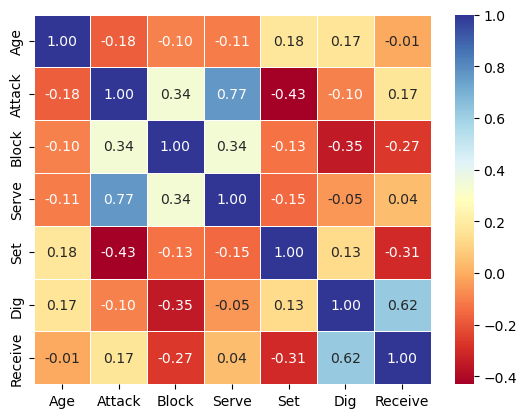

In [56]:
sns.heatmap(corr, annot=True, cmap='RdYlBu', fmt='.2f', linewidths=0.5)
plt.show()

In [57]:
df.head()

,Player,Country,Age,Attack,Block,Serve,Set,Dig,Receive,Position
0,Ichikawa Yuki,Japan,28,15.80,1.13,1.40,0.07,4.80,5.60,OH
1,Romano Yuri,Italy,26,12.33,1.07,1.47,0.00,3.87,0.00,OP
2,Abdel-Aziz Nimir,Nederland,31,15.33,0.67,2.08,0.00,3.17,0.25,OP
3,Herrera Jaime Jesus,Cuba,28,15.00,0.92,1.75,0.00,3.33,0.17,OP
4,Takahashi Ran,Japan,22,11.53,0.67,1.00,0.07,6.40,5.07,OH


In [58]:
df['Age'].agg(['mean','median','min','max'])

mean      27.80916
median    27.00000
min       19.00000
max       41.00000
Name: Age, dtype: float64

In [59]:
player_attack = df.groupby('Player')['Attack'].agg(['mean','median','min','max']).sort_values(by='max',ascending=False).head(10)

C:\Users\masth\AppData\Local\Temp\ipykernel_8888\797727692.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


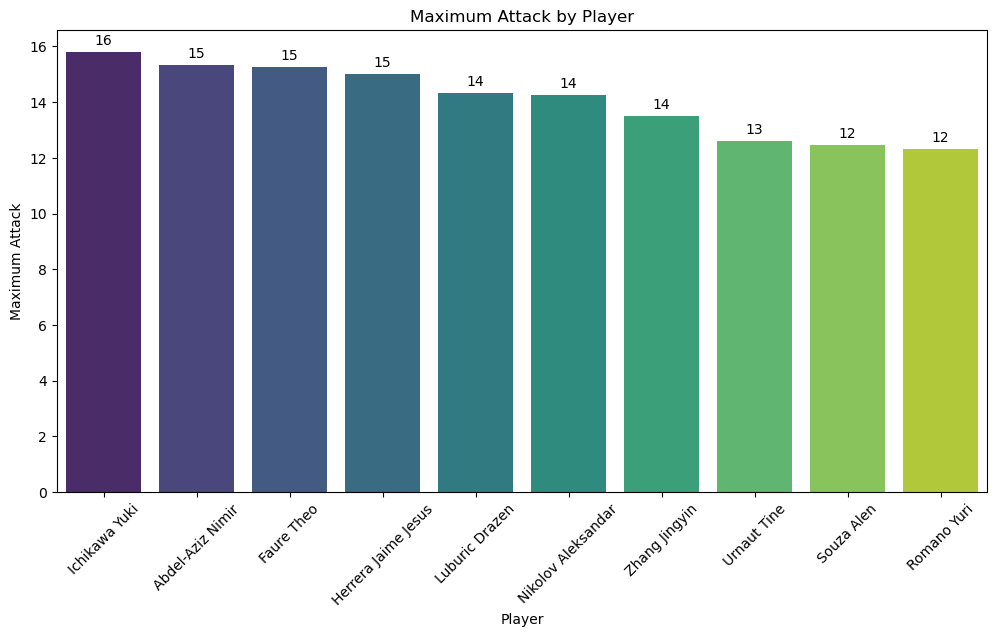

In [60]:


plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=player_attack.index,
    y=player_attack['max'],
    palette='viridis'
)

# Add labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title('Maximum Attack by Player')
plt.xlabel('Player')
plt.ylabel('Maximum Attack')
plt.xticks(rotation=45)

plt.show()

In [61]:
df.groupby(['Country','Position']).count()

Player  Age  Attack  Block  Serve  Set  Dig  Receive
Country   Position                                                      
Argentina L              1    1       1      1      1    1    1        1
          MB             2    2       2      2      2    2    2        2
          OH             2    2       2      2      2    2    2        2
          OP             2    2       2      2      2    2    2        2
          S              1    1       1      1      1    1    1        1
...                    ...  ...     ...    ...    ...  ...  ...      ...
USA       L              1    1       1      1      1    1    1        1
          MB             3    3       3      3      3    3    3        3
          OH             3    3       3      3      3    3    3        3
          OP             1    1       1      1      1    1    1        1
          S              1    1       1      1      1    1    1        1

[79 rows x 8 columns]

In [62]:
df[['Country','Position']].value_counts().sort_values(ascending=False)

Country    Position
Slovenia   OH          4
Poland     OH          4
USA        MB          3
France     OP          3
Bulgaria   OH          3
                      ..
Japan      L           1
Italy      S           1
Argentina  S           1
Brazil     L           1
USA        S           1
Name: count, Length: 79, dtype: int64

In [64]:
position_c = df['Position'].value_counts()

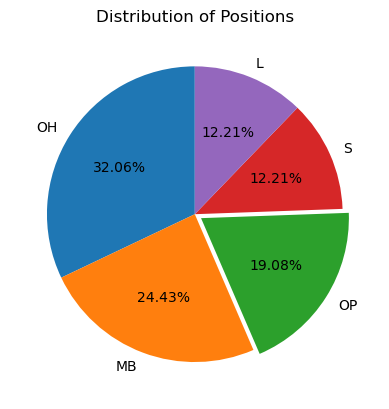

In [70]:
plt.pie(position_c, labels=position_c.index, autopct="%1.2f%%",startangle=90, explode=[0,0,0.05,0,0])
plt.title("Distribution of Positions")
plt.show()

In [73]:
Con_attacks = df.groupby('Country')['Attack'].mean().sort_values(ascending=False)

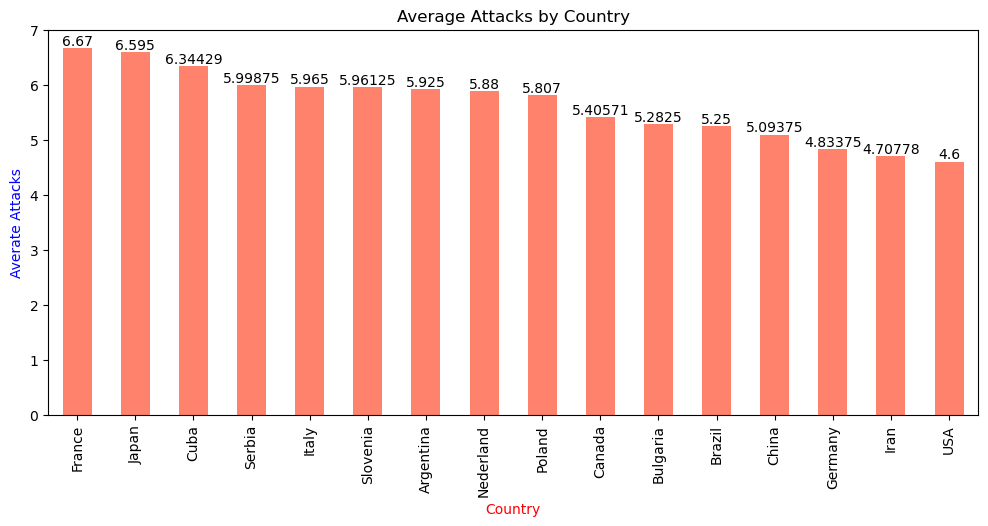

In [82]:
plt.figure(figsize=(12,5))
ax =Con_attacks.plot(kind='bar', color='tomato', alpha=0.8)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Average Attacks by Country")
plt.xlabel("Country", color="red")
plt.ylabel("Averate Attacks", color='blue')
plt.show()

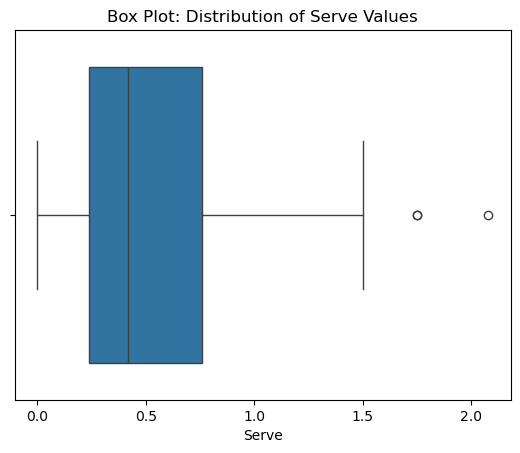

In [85]:
sns.boxplot(x=df['Serve'])
plt.title("Box Plot: Distribution of Serve Values")
plt.show()

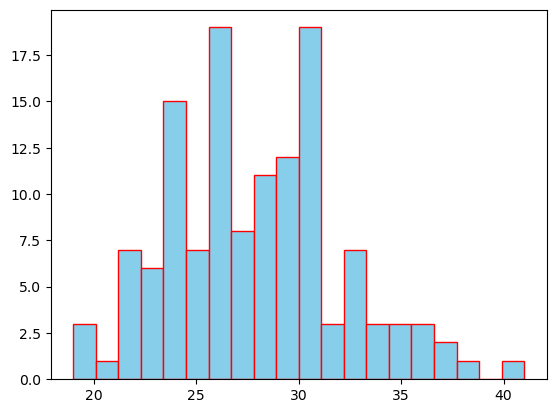

In [86]:
plt.hist(df['Age'], bins=20,color='skyblue', edgecolor='red')
plt.show()

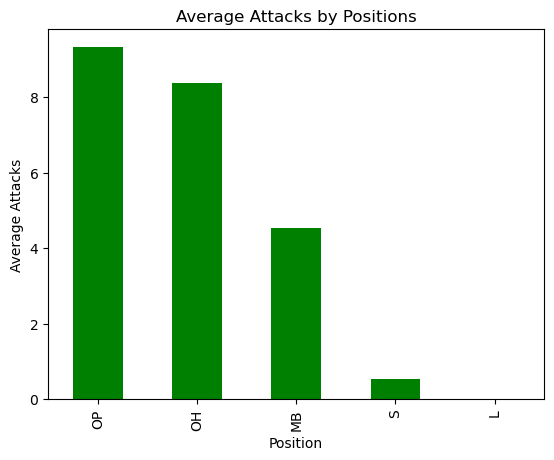

In [92]:
df.groupby('Position')['Attack'].mean().sort_values(ascending=False).plot(kind='bar', color='green')
plt.title("Average Attacks by Positions")
plt.xlabel("Position")
plt.ylabel("Average Attacks")
plt.show()